<a href="https://colab.research.google.com/github/njw257/bigdataprogramming_hackathon/blob/main/garbage_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 쓰레기 이미지 분류 최종 모델
계명대학교 경영정보학과 남종욱

원본 실험에서 데이터 준비와 최종 `FilterCNN`·`WideCNN`, `run_epoch`, `fit_experiment`, 시험 평가만 추렸습니다.
하이퍼파라미터 탐색 셀은 제외했으며 최적 설정으로 20 epoch를 처음부터 학습합니다. 사전 학습 가중치는 포함하지 않습니다.
원래 저장·복구 부분은 제거하고 선택 가중치를 메모리에서 시험 평가에 연결합니다.

**셀 아래에 보존된 출력은 원본의 이전 실행 결과입니다. 이 정리본을 새로 실행한 결과가 아닙니다.**
원래 순서대로 실행하면 데이터 수집부터 학습·시험까지 진행되며 CSV·그림·최종 모델 파일이 생성됩니다.

## 데이터 수집

In [ ]:
# Kaggle 데이터 접근용 라이브러리 설치
%pip install -q kagglehub

In [ ]:
import kagglehub
from pathlib import Path

# 지정 데이터셋을 가져오고 저장 경로 확인
data_path = Path(kagglehub.dataset_download("mostafaabla/garbage-classification"))
print("데이터 경로:", data_path)

# 폴더 구조 확인
print("내부 항목:", sorted(p.name for p in data_path.iterdir()))

Using Colab cache for faster access to the 'garbage-classification' dataset.
데이터 경로: /kaggle/input/garbage-classification
내부 항목: ['garbage_classification']


In [ ]:
# 클래스별 폴더가 있는 경로
image_dir = data_path / "garbage_classification"

# 클래스별 이미지 수 집계
extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
class_counts = {
    folder.name: sum(
        p.is_file() and p.suffix.lower() in extensions
        for p in folder.rglob("*")
    )
    for folder in sorted(image_dir.iterdir())
    if folder.is_dir()
}

for name, count in class_counts.items():
    print(f"{name}: {count:,}장")

print(f"\n클래스 수: {len(class_counts)}개")
print(f"전체 이미지: {sum(class_counts.values()):,}장")

battery: 945장
biological: 985장
brown-glass: 607장
cardboard: 891장
clothes: 5,325장
green-glass: 629장
metal: 769장
paper: 1,050장
plastic: 865장
shoes: 1,977장
trash: 697장
white-glass: 775장

클래스 수: 12개
전체 이미지: 15,515장


## EDA

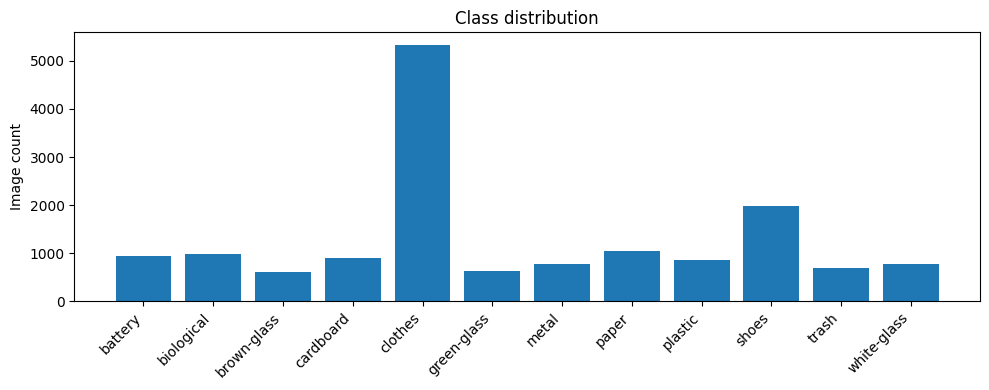

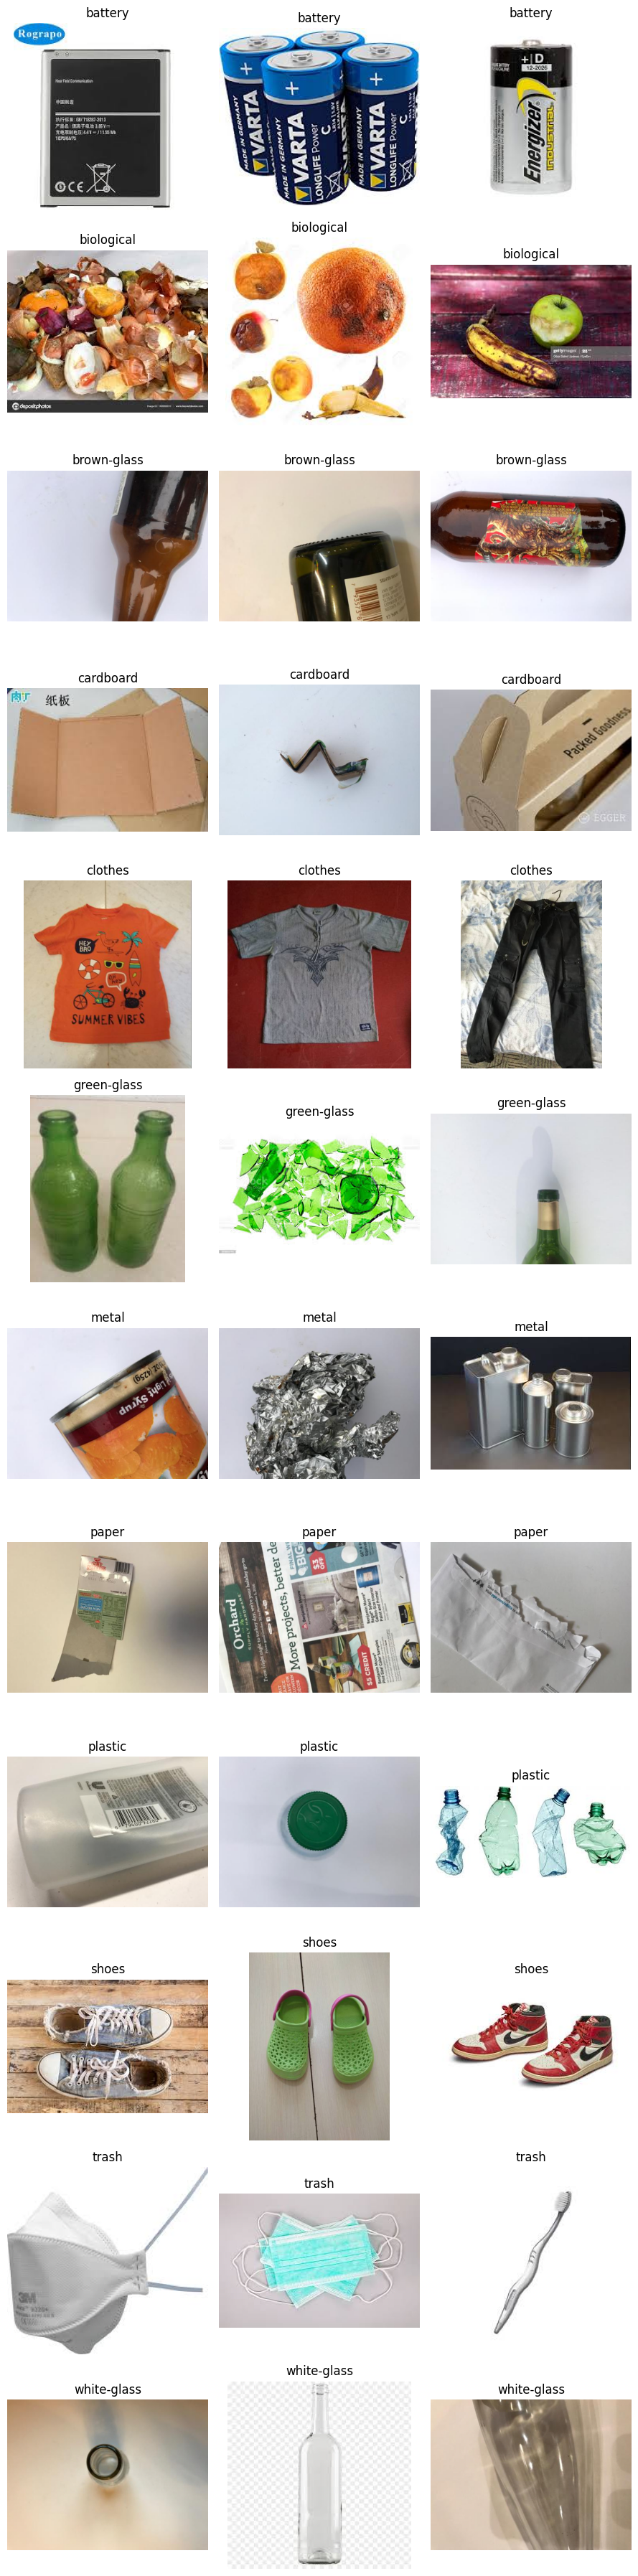

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image

# 클래스별 이미지 수 시각화
plt.figure(figsize=(10, 4))
plt.bar(class_counts.keys(), class_counts.values())
plt.xticks(rotation=45, ha="right")
plt.ylabel("Image count")
plt.title("Class distribution")
plt.tight_layout()
plt.show()

# 클래스별 이미지 3장을 고정된 난수로 선택
rng = random.Random(42)
fig, axes = plt.subplots(len(class_counts), 3, figsize=(9, 3 * len(class_counts)))

for row, name in enumerate(class_counts):
    files = sorted(
        p for p in (image_dir / name).rglob("*")
        if p.is_file() and p.suffix.lower() in extensions
    )
    for col, path in enumerate(rng.sample(files, 3)):
        with Image.open(path) as img:
            axes[row, col].imshow(img.convert("RGB"))
        axes[row, col].set_title(name)
        axes[row, col].axis("off")

plt.tight_layout()
plt.show()

## 이미지 상태 확인

In [ ]:
import pandas as pd

records, bad_files = [], []

# 모든 이미지를 읽어 크기·색상 모드·손상 여부 확인
for name in class_counts:
    for path in sorted((image_dir / name).rglob("*")):
        if not path.is_file() or path.suffix.lower() not in extensions:
            continue
        try:
            with Image.open(path) as img:
                img.load()  # 실제 픽셀까지 읽어 오류 확인
                records.append({
                    "path": str(path), "class": name,
                    "width": img.width, "height": img.height, "mode": img.mode
                })
        except (OSError, ValueError) as error:
            bad_files.append((str(path), str(error)))

images_df = pd.DataFrame(records)

print("정상 이미지:", len(images_df))
print("손상 이미지:", len(bad_files))
print("\n이미지 크기 요약:\n", images_df[["width", "height"]].describe().round(1))
print("\n색상 모드별 수량:\n", images_df["mode"].value_counts())
print("\n손상 파일 예시:", bad_files[:5])

정상 이미지: 15515
손상 이미지: 0

이미지 크기 요약:
          width   height
count  15515.0  15515.0
mean     349.8    351.7
std      117.5    149.4
min       51.0    100.0
25%      234.0    224.0
50%      400.0    384.0
75%      400.0    533.0
max      888.0    936.0

색상 모드별 수량:
 mode
RGB    15481
P         34
Name: count, dtype: int64

손상 파일 예시: []


## 중복 확인

In [ ]:
import hashlib

# 파일 내용으로 해시 생성: 내용이 같으면 같은 해시가 나옵니다.
images_df["hash"] = images_df["path"].apply(
    lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
)

# 중복 그룹의 이미지 수와 클래스 확인
duplicates = images_df[images_df.duplicated("hash", keep=False)]
duplicate_groups = duplicates.groupby("hash").agg(
    count=("path", "size"),
    classes=("class", lambda x: sorted(set(x)))
)

print("중복 그룹 수:", len(duplicate_groups))
print("중복 여분 이미지 수:", images_df.duplicated("hash").sum())
print("클래스가 서로 다른 중복 그룹 수:",
      duplicate_groups["classes"].apply(len).gt(1).sum())
print("\n중복 그룹 예시:\n", duplicate_groups.head(10).to_string(index=False))

중복 그룹 수: 18
중복 여분 이미지 수: 19
클래스가 서로 다른 중복 그룹 수: 3

중복 그룹 예시:
  count       classes
     2 [green-glass]
     2 [green-glass]
     2 [green-glass]
     2 [green-glass]
     2 [green-glass]
     2     [clothes]
     2 [green-glass]
     2 [green-glass]
     2 [green-glass]
     2 [green-glass]


      class                                                                                       path
      metal             /kaggle/input/garbage-classification/garbage_classification/metal/metal459.jpg
white-glass /kaggle/input/garbage-classification/garbage_classification/white-glass/white-glass412.jpg 

      class                                                                                       path
    plastic         /kaggle/input/garbage-classification/garbage_classification/plastic/plastic556.jpg
white-glass /kaggle/input/garbage-classification/garbage_classification/white-glass/white-glass761.jpg 

      class                                                                                       path
    plastic         /kaggle/input/garbage-classification/garbage_classification/plastic/plastic159.jpg
white-glass /kaggle/input/garbage-classification/garbage_classification/white-glass/white-glass129.jpg 



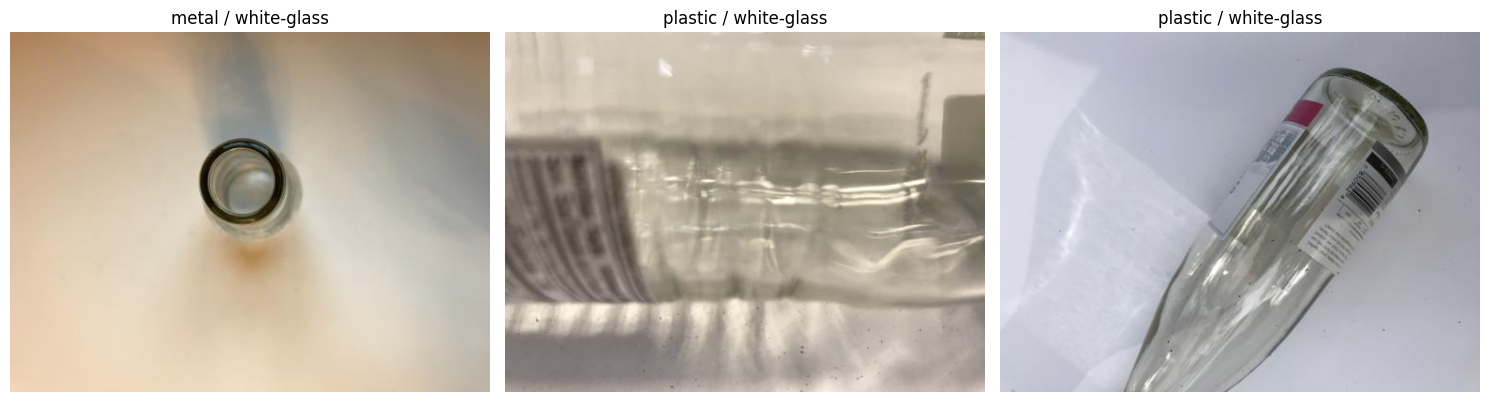

In [ ]:
# 서로 다른 클래스에 들어 있는 중복 그룹 선택
conflict_hashes = duplicate_groups.index[
    duplicate_groups["classes"].apply(len) > 1
]

# 그룹별 대표 이미지와 부여된 클래스 표시
fig, axes = plt.subplots(1, len(conflict_hashes),
                         figsize=(5 * len(conflict_hashes), 4), squeeze=False)

for ax, file_hash in zip(axes.flat, conflict_hashes):
    group = images_df[images_df["hash"] == file_hash]

    with Image.open(group.iloc[0]["path"]) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(" / ".join(sorted(group["class"].unique())))
    ax.axis("off")
    print(group[["class", "path"]].to_string(index=False), "\n")

plt.tight_layout()
plt.show()

## 중복 정제

In [ ]:
# 레이블이 충돌하는 이미지 제외: 제외 목록은 보고서용으로 보관
conflict_rows = images_df[images_df["hash"].isin(conflict_hashes)].copy()
clean_df = images_df[~images_df["hash"].isin(conflict_hashes)].copy()

# 같은 클래스의 동일 파일은 한 장만 유지
duplicate_rows = clean_df[clean_df.duplicated("hash")].copy()
clean_df = clean_df.drop_duplicates("hash").reset_index(drop=True)

print("레이블 충돌로 제외:", len(conflict_rows))
print("동일 클래스 중복으로 제외:", len(duplicate_rows))
print("최종 이미지 수:", len(clean_df))
print("\n클래스별 수량:\n", clean_df["class"].value_counts().sort_index())

레이블 충돌로 제외: 6
동일 클래스 중복으로 제외: 16
최종 이미지 수: 15493

클래스별 수량:
 class
battery         945
biological      985
brown-glass     607
cardboard       891
clothes        5324
green-glass     614
metal           768
paper          1050
plastic         863
shoes          1977
trash           697
white-glass     772
Name: count, dtype: int64


## 데이터 분할

In [ ]:
from sklearn.model_selection import train_test_split

# 클래스 비율을 유지하여 학습 80%, 나머지 20%로 분리
train_df, remaining_df = train_test_split(
    clean_df, test_size=0.2, stratify=clean_df["class"], random_state=42
)

# 나머지를 검증 10%, 시험 10%로 분리
val_df, test_df = train_test_split(
    remaining_df, test_size=0.5, stratify=remaining_df["class"], random_state=42
)

# 분할 목록 저장: 이후 실험에서도 동일하게 사용
split_df = pd.concat([
    train_df.assign(split="train"),
    val_df.assign(split="val"),
    test_df.assign(split="test")
], ignore_index=True)
split_df.to_csv("data_split.csv", index=False)

# 클래스별 분할 수량 확인
print(pd.crosstab(split_df["class"], split_df["split"])[["train", "val", "test"]])
print(f"\n학습: {len(train_df):,} / 검증: {len(val_df):,} / 시험: {len(test_df):,}")

split        train  val  test
class                        
battery        756   94    95
biological     788   98    99
brown-glass    486   61    60
cardboard      713   89    89
clothes       4259  532   533
green-glass    491   62    61
metal          614   77    77
paper          840  105   105
plastic        690   86    87
shoes         1581  198   198
trash          558   70    69
white-glass    618   77    77

학습: 12,394 / 검증: 1,549 / 시험: 1,550


## 전처리와 데이터 로더

In [ ]:
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 클래스 이름을 정수 레이블로 변환: 모든 데이터에 같은 매핑 사용
classes = sorted(clean_df["class"].unique())
class_to_idx = {name: idx for idx, name in enumerate(classes)}

# 크기를 통일하고 픽셀 값을 [0, 1]에서 [-1, 1]로 변환
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize([0.5] * 3, [0.5] * 3)
])

class GarbageDataset(Dataset):
    def __init__(self, frame, transform):
        self.frame = frame.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        with Image.open(row["path"]) as img:
            image = self.transform(img.convert("RGB"))
        return image, class_to_idx[row["class"]]

# 학습 데이터만 순서를 섞고, 마지막의 작은 배치도 포함
train_loader = DataLoader(
    GarbageDataset(train_df, transform), batch_size=32, shuffle=True
)
val_loader = DataLoader(
    GarbageDataset(val_df, transform), batch_size=32, shuffle=False
)
test_loader = DataLoader(
    GarbageDataset(test_df, transform), batch_size=32, shuffle=False
)

# 학습 배치 하나로 입력 형태 확인
images, labels = next(iter(train_loader))
print("사용 장치:", device)
print("이미지:", images.shape, images.dtype)
print("레이블:", labels.shape, labels.dtype)
print("클래스 매핑:", class_to_idx)

사용 장치: cuda
이미지: torch.Size([32, 3, 128, 128]) torch.float32
레이블: torch.Size([32]) torch.int64
클래스 매핑: {'battery': 0, 'biological': 1, 'brown-glass': 2, 'cardboard': 3, 'clothes': 4, 'green-glass': 5, 'metal': 6, 'paper': 7, 'plastic': 8, 'shoes': 9, 'trash': 10, 'white-glass': 11}


## 기존 실험에서 선택한 최종 모델

In [ ]:
from torch import nn

class FilterCNN(nn.Module):
    def __init__(self, num_classes, channels):
        super().__init__()
        layers = []
        cin = 3

        for cout in channels[:3]:
            layers += [
                nn.Conv2d(cin, cout, 3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.MaxPool2d(2)
            ]
            cin = cout

        self.features = nn.Sequential(*layers)

        # 기존 DeeperCNN과 초기화 순서를 맞춤
        self.classifier = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Linear(channels[3], num_classes)
        )
        self.features.extend([
            nn.Conv2d(channels[2], channels[3], 3, padding=1),
            nn.BatchNorm2d(channels[3]),
            nn.ReLU(),
            nn.MaxPool2d(2)
        ])

    def forward(self, x):
        return self.classifier(self.features(x))

class WideCNN(FilterCNN):
    def __init__(self, num_classes):
        super().__init__(num_classes, (64, 128, 256, 256))


In [ ]:
criterion = nn.CrossEntropyLoss()

# optimizer가 주어지면 학습, 없으면 검증
def run_epoch(model, loader, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum, correct, total = 0.0, 0, 0

    for x, y in loader:
        x, y = x.to(device), y.to(device)

        with torch.set_grad_enabled(training):
            logits = model(x)
            loss = criterion(logits, y)

            if training:
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

        loss_sum += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        total += y.size(0)

    return loss_sum / total, correct / total

In [ ]:
experiment_results = {}
train_set = GarbageDataset(train_df, transform)

def fit_experiment(name, model_factory, dataset, lr=0.005, epochs=20):
    out_dir = Path("lr_search/structure")
    out_dir.mkdir(parents=True, exist_ok=True)

    torch.manual_seed(42)
    model = model_factory().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    generator = torch.Generator().manual_seed(42)
    loader = DataLoader(
        dataset, batch_size=32, shuffle=True, generator=generator
    )

    history, best_state = [], None
    best_acc, start_epoch = -1.0, 1


    print("파라미터 수:", sum(p.numel() for p in model.parameters()))

    for epoch in range(start_epoch, epochs + 1):
        train_loss, train_acc = run_epoch(model, loader, optimizer)
        val_loss, val_acc = run_epoch(model, val_loader)

        history.append({
            "epoch": epoch,
            "train_loss": train_loss, "val_loss": val_loss,
            "train_acc": train_acc, "val_acc": val_acc
        })

        if val_acc > best_acc:
            best_acc = val_acc
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        pd.DataFrame(history).to_csv(
            out_dir / f"history_{name}.csv", index=False
        )

        print(
            f"{name} | Epoch {epoch:02d}/{epochs} | "
            f"Train loss {train_loss:.4f}, acc {train_acc:.2%} | "
            f"Val loss {val_loss:.4f}, acc {val_acc:.2%}"
        )

    # 중간 파일 대신 평가에 필요한 최적 가중치만 메모리에 보관
    experiment_results[name] = {
        "best_model_state": best_state,
        "best_val_acc": best_acc,
        "history": history,
        "class_to_idx": class_to_idx,
        "image_size": 128,
        "mean": [0.5] * 3, "std": [0.5] * 3
    }

    return pd.DataFrame(history)


## 최적 설정으로 학습
아래 출력은 원본의 wide 모델 학습 기록만 발췌했습니다.

In [ ]:
# 원본의 필터 수 비교 셀에서 최종 wide 모델 학습 부분만 유지
width_frames = {}
for name, model_class in [("wide", WideCNN)]:
    width_frames[name] = fit_experiment(
        f"width_{name}",
        lambda cls=model_class: cls(len(classes)),
        train_set,
        lr=0.005,
        epochs=20
    )


파라미터 수: 965388
width_wide | Epoch 01/20 | Train loss 1.4577, acc 52.50% | Val loss 1.4536, acc 54.23%
width_wide | Epoch 02/20 | Train loss 1.2319, acc 59.80% | Val loss 1.1933, acc 61.33%
width_wide | Epoch 03/20 | Train loss 1.0929, acc 63.90% | Val loss 1.0666, acc 65.59%
width_wide | Epoch 04/20 | Train loss 0.9884, acc 67.71% | Val loss 1.0002, acc 67.27%
width_wide | Epoch 05/20 | Train loss 0.8885, acc 70.69% | Val loss 0.9181, acc 70.69%
width_wide | Epoch 06/20 | Train loss 0.8149, acc 72.86% | Val loss 0.9886, acc 67.98%
width_wide | Epoch 07/20 | Train loss 0.7427, acc 75.19% | Val loss 0.8194, acc 74.37%
width_wide | Epoch 08/20 | Train loss 0.6789, acc 77.66% | Val loss 0.8421, acc 73.79%
width_wide | Epoch 09/20 | Train loss 0.6274, acc 79.40% | Val loss 0.8483, acc 72.76%
width_wide | Epoch 10/20 | Train loss 0.5621, acc 81.56% | Val loss 0.7131, acc 78.11%
width_wide | Epoch 11/20 | Train loss 0.5198, acc 83.15% | Val loss 0.8102, acc 76.44%
width_wide | Epoch 12/20 | T

## 최종 시험 평가
원본 시험 평가 셀을 유지하고 입력 모델만 메모리의 최적 가중치로 연결했습니다.

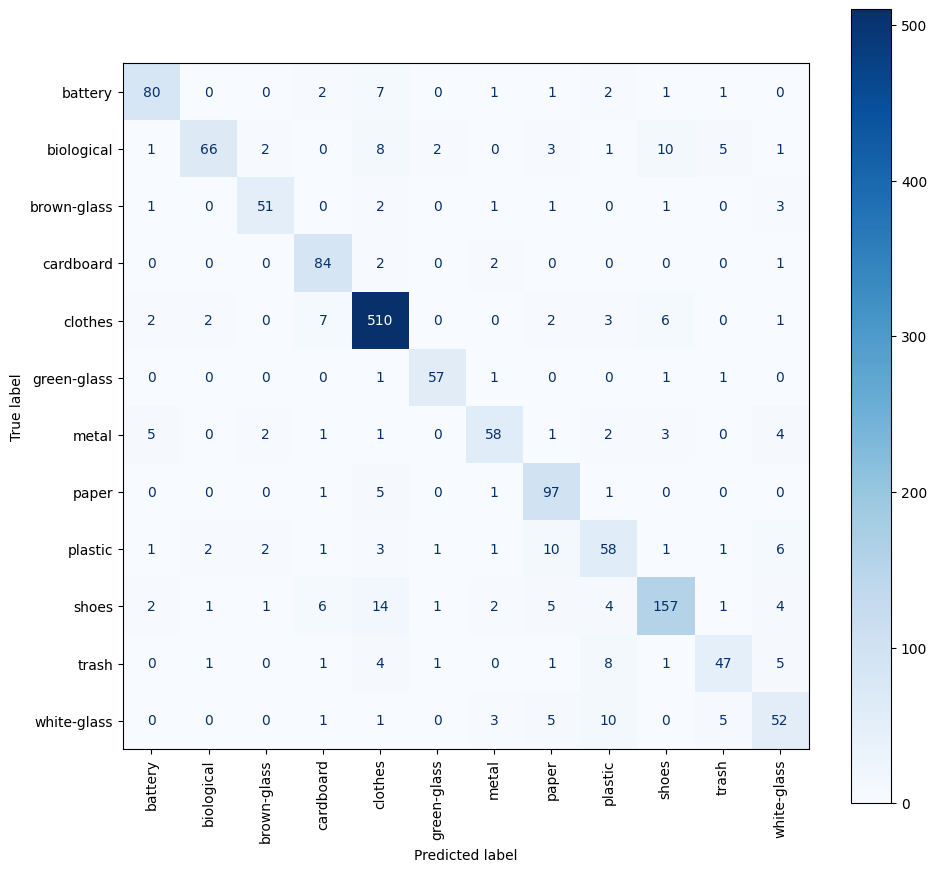

최종 시험 성능:
  test_images  test_loss  accuracy  macro_f1  macro_recall
        1550     0.5212    0.8497    0.8116        0.8073

클래스별 성능:
               precision  recall  f1-score  support
battery           0.870   0.842     0.856     95.0
biological        0.917   0.667     0.772     99.0
brown-glass       0.879   0.850     0.864     60.0
cardboard         0.808   0.944     0.870     89.0
clothes           0.914   0.957     0.935    533.0
green-glass       0.919   0.934     0.927     61.0
metal             0.829   0.753     0.789     77.0
paper             0.770   0.924     0.840    105.0
plastic           0.652   0.667     0.659     87.0
shoes             0.867   0.793     0.828    198.0
trash             0.770   0.681     0.723     69.0
white-glass       0.675   0.675     0.675     77.0
macro avg         0.822   0.807     0.812   1550.0
weighted avg      0.851   0.850     0.848   1550.0

제출용 모델 크기: 3.70 MB


In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

out_dir = Path("lr_search/final")
out_dir.mkdir(exist_ok=True)

# 검증 결과로 선택한 메모리의 최적 모델 적용
saved = experiment_results["width_wide"]
assert saved["class_to_idx"] == class_to_idx
assert saved["image_size"] == 128

model = WideCNN(len(classes)).to(device)
model.load_state_dict(saved["best_model_state"])
model.eval()

# optimizer·중복 가중치를 제외한 제출용 모델 저장
history_frame = pd.DataFrame(saved["history"])
best_epoch = int(history_frame.loc[
    history_frame["val_acc"].idxmax(), "epoch"
])

torch.save({
    "model_name": "WideCNN",
    "model_state": saved["best_model_state"],
    "class_to_idx": class_to_idx,
    "channels": [64, 128, 256, 256],
    "image_size": 128,
    "mean": saved["mean"],
    "std": saved["std"],
    "selected_epoch": best_epoch,
    "validation_accuracy": saved["best_val_acc"]
}, out_dir / "final_model.pth")

# 시험 데이터에 기존과 동일한 전처리 적용
test_df = split_df[split_df["split"] == "test"].copy()
test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(saved["mean"], saved["std"])
])
test_loader = DataLoader(
    GarbageDataset(test_df, test_transform),
    batch_size=32, shuffle=False
)

# 시험 데이터 전체 평가
true_labels, pred_labels = [], []
loss_sum = 0.0

with torch.no_grad():
    for x, y in test_loader:
        logits = model(x.to(device))
        loss_sum += criterion(logits, y.to(device)).item() * y.size(0)
        true_labels.extend(y.tolist())
        pred_labels.extend(logits.argmax(1).cpu().tolist())

report = classification_report(
    true_labels, pred_labels,
    labels=list(range(len(classes))),
    target_names=classes,
    output_dict=True, zero_division=0
)

summary = pd.DataFrame([{
    "test_images": len(test_df),
    "test_loss": loss_sum / len(test_df),
    "accuracy": report["accuracy"],
    "macro_f1": report["macro avg"]["f1-score"],
    "macro_recall": report["macro avg"]["recall"]
}])
summary.to_csv(out_dir / "test_summary.csv", index=False)

# 클래스별 평가와 이미지별 예측 저장
report_df = pd.DataFrame({
    name: report[name] for name in classes + ["macro avg", "weighted avg"]
}).T
report_df.to_csv(out_dir / "test_classification_report.csv")

predictions = test_df[["path", "class"]].copy()
predictions["prediction"] = [classes[i] for i in pred_labels]
predictions.to_csv(out_dir / "test_predictions.csv", index=False)

# 혼동행렬 저장
fig, ax = plt.subplots(figsize=(10, 9))
ConfusionMatrixDisplay.from_predictions(
    true_labels, pred_labels,
    labels=list(range(len(classes))),
    display_labels=classes,
    cmap="Blues", values_format="d",
    xticks_rotation=90, ax=ax
)
plt.tight_layout()
plt.savefig(out_dir / "test_confusion_matrix.png", dpi=150)
plt.show()

print("최종 시험 성능:\n", summary.round(4).to_string(index=False))
print("\n클래스별 성능:\n", report_df.round(3).to_string())
print(f"\n제출용 모델 크기: {(out_dir / 'final_model.pth').stat().st_size / 1024**2:.2f} MB")

## 학습 곡선과 최종 시험점
원본의 그래프 코드를 사용합니다. 이 셀의 새 출력은 학습·시험 셀을 실행한 뒤 생성됩니다.

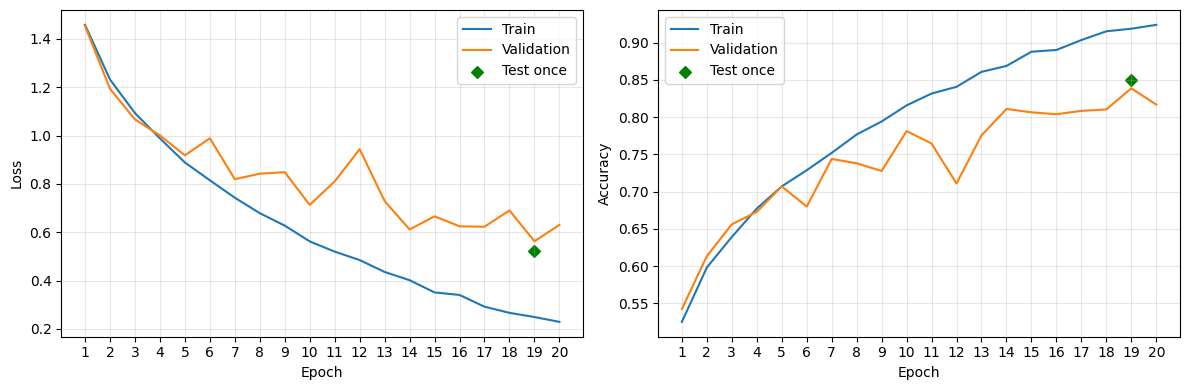

In [ ]:
history_df = width_frames["wide"]
# 학습·검증 곡선 시각화
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, metric in zip(axes, ["loss", "acc"]):
    ax.plot(history_df["epoch"], history_df[f"train_{metric}"], label="Train")
    ax.plot(history_df["epoch"], history_df[f"val_{metric}"], label="Validation")
    selected_epoch = int(history_df.loc[history_df["val_acc"].idxmax(), "epoch"])
    test_value = summary.iloc[0]["test_loss" if metric == "loss" else "accuracy"]
    ax.scatter([selected_epoch], [test_value], marker="D", color="green", label="Test once")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss" if metric == "loss" else "Accuracy")
    ax.set_xticks(history_df["epoch"])
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()
